# Sunday Project: Data Quality, Insights & CSV Operations
**AI Engineering Bootcamp | Assignment-03**

| Part | Topic
|---|---|
| **Part A** | Data Quality & Basic Insights
| **Part B** | CSV File Handling & Manipulation

**How to run:** place `sales_raw.csv` in the same folder as this notebook (relative paths are used, so it works in Jupyter and Colab) and choose *Run all*.
Files produced: `cleaned_sales.csv`, `revenue_by_category.png`, `revenue_by_region.png`, `sales_updated.csv`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

RAW_FILE = "sales_raw.csv"          # input: never modified
CLEAN_FILE = "cleaned_sales.csv"    # output of Part A
UPDATED_FILE = "sales_updated.csv"  # output of Part B

---
# PART A: Data Quality & Basic Insights
## 1. Load and inspect

In [2]:
raw = pd.read_csv(RAW_FILE)   # the original is only read, never overwritten
raw.head()

,transaction_id,sale_date,region,category,quantity,unit_price
0,1001,10/1/2026,North,food,2.0,120
1,1002,10/1/2026,South,Books,1.0,250
2,1003,10/2/2026,North,Food,3.0,110
3,1004,10/2/2026,East,Stationery,4.0,50
4,1005,10/3/2026,SOUTH,books,2.0,250


In [3]:
print("Shape (rows, columns):", raw.shape)
print("\nColumn names:", list(raw.columns))
print("\nData types:")
print(raw.dtypes)

Shape (rows, columns): (21, 6)

Column names: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price']

Data types:
transaction_id      int64
sale_date             str
region                str
category              str
quantity          float64
unit_price            str
dtype: object


In [4]:
print("Missing values per column:")
print(raw.isna().sum())
print("\nDuplicate rows:", raw.duplicated().sum())

Missing values per column:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Duplicate rows: 1


**What the inspection shows**
- `quantity`, `region` and `unit_price` each have a missing value.
- `unit_price` is read as text (not a number), so at least one entry is not numeric (`"invalid"`).
- One row is an exact duplicate (transaction `1003`).
- `region` and `category` have stray spaces and inconsistent capitalisation (` food `, `SOUTH`, `books`), which `isna()` and `duplicated()` cannot see.
- `sale_date` is text, and one entry is not a date (`invalid-date`).
- There is a negative quantity (`-2`) and a suspicious price of `10000` for a Stationery item.

## 2. Clean the dataset

### Cleaning rules and why

| Problem | Rule | Reason |
|---|---|---|
| Extra spaces / mixed case in `region`, `category` | `.str.strip().str.title()` | `" food "`, `"Food"` must count as one group, otherwise `groupby` splits it. |
| Wrong data types | Convert `sale_date` to datetime and `unit_price` to numeric (`errors="coerce"`) | Bad values become `NaN`/`NaT`, so they can be found and handled. |
| Duplicate rows | `drop_duplicates()`, keep the first | The same sale must not be counted twice in revenue. |
| Missing `quantity` or `unit_price` | **Drop the row** | Revenue = quantity × unit_price. Guessing either number would make up revenue. |
| Invalid price (`"invalid"`, non-numeric) | Drop the row | Same reason, and the true price is unknowable. |
| Invalid price (outlier): price above 10× its category median | Drop the row | A 10,000 stationery price against a normal 40 to 60 looks like a data-entry error and would dominate every total. |
| Negative quantity | Drop the row | A sale cannot have negative units. It is probably a return or an entry error. |
| Invalid `sale_date` | Drop the row | A sale with no valid date cannot be trusted or placed in time. |
| Missing `region` | Fill with `"Unknown"` and keep the row | Quantity and price are fine, so the revenue is real. Dropping it would understate the total. |

In [5]:
df = raw.copy()
log = [("Raw data", len(df))]

# 1) Trim spaces and standardise text
for col in ["region", "category"]:
    df[col] = df[col].str.strip().str.title()

# 2) Fix data types (bad values become NaN / NaT instead of crashing)
df["sale_date"] = pd.to_datetime(df["sale_date"], format="%m/%d/%Y", errors="coerce")
df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")

# 3) Missing region -> "Unknown" (the sale itself is still valid)
df["region"] = df["region"].fillna("Unknown")

# 4) Remove duplicate rows
df = df.drop_duplicates()
log.append(("After removing duplicates", len(df)))

# 5) Remove rows where revenue cannot be calculated reliably
df = df.dropna(subset=["quantity", "unit_price"])
log.append(("After dropping missing / non-numeric quantity or price", len(df)))

# 6) Remove invalid values: negative quantity, invalid dates, price outliers
df = df[df["quantity"] > 0]
log.append(("After dropping negative quantity", len(df)))

df = df.dropna(subset=["sale_date"])
log.append(("After dropping invalid dates", len(df)))

category_median = df.groupby("category")["unit_price"].transform("median")
df = df[df["unit_price"] <= 10 * category_median]
log.append(("After dropping price outliers", len(df)))

df["quantity"] = df["quantity"].astype(int)
df = df.reset_index(drop=True)

In [6]:
# Which transactions were removed, and compare row counts before and after
removed = sorted(set(raw["transaction_id"]) - set(df["transaction_id"]))
print("Removed transaction_ids:", removed)
print("(1003 appears twice in the raw file; the first copy is kept)\n")

print(pd.DataFrame(log, columns=["Step", "Rows remaining"]).to_string(index=False))
print(f"\nRows BEFORE cleaning: {len(raw)}")
print(f"Rows AFTER cleaning : {len(df)}")
print(f"Rows removed        : {len(raw) - len(df)}")

print("\nMissing values after cleaning:")
print(df.isna().sum())
print("Duplicates after cleaning:", df.duplicated().sum())
print("Regions   :", sorted(df['region'].unique()))
print("Categories:", sorted(df['category'].unique()))

Removed transaction_ids: [1006, 1010, 1011, 1013, 1014, 1016]
(1003 appears twice in the raw file; the first copy is kept)

                                                  Step  Rows remaining
                                              Raw data              21
                             After removing duplicates              20
After dropping missing / non-numeric quantity or price              17
                      After dropping negative quantity              16
                          After dropping invalid dates              15
                         After dropping price outliers              14

Rows BEFORE cleaning: 21
Rows AFTER cleaning : 14
Rows removed        : 7

Missing values after cleaning:
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64
Duplicates after cleaning: 0
Regions   : ['East', 'North', 'South', 'Unknown', 'West']
Categories: ['Books', 'Food', 'Stationery']


## 3. Calculate and analyze

In [7]:
df["revenue"] = df["quantity"] * df["unit_price"]
df.head()

,transaction_id,sale_date,region,category,quantity,unit_price,revenue
0,1001,2026-10-01,North,Food,2,120.0,240.0
1,1002,2026-10-01,South,Books,1,250.0,250.0
2,1003,2026-10-02,North,Food,3,110.0,330.0
3,1004,2026-10-02,East,Stationery,4,50.0,200.0
4,1005,2026-10-03,South,Books,2,250.0,500.0


In [8]:
by_category = (df.groupby("category")["revenue"].sum()
                 .sort_values(ascending=False))
by_region = (df.groupby("region")["revenue"].sum()
               .sort_values(ascending=False))

print("Total revenue:", df["revenue"].sum())
print("\nRevenue by category:\n", by_category)
print("\nRevenue by region:\n", by_region)

# Extra detail used in the findings
summary = df.groupby("category").agg(
    revenue=("revenue", "sum"),
    transactions=("transaction_id", "count"),
    units=("quantity", "sum"),
)
summary["share_%"] = (summary["revenue"] / summary["revenue"].sum() * 100).round(1)
summary["revenue_per_unit"] = (summary["revenue"] / summary["units"]).round(1)
summary.sort_values("revenue", ascending=False)

Total revenue: 4175.0

Revenue by category:
 category
Food          1945.0
Books         1770.0
Stationery     460.0
Name: revenue, dtype: float64

Revenue by region:
 region
North      1470.0
South      1035.0
East        740.0
West        530.0
Unknown     400.0
Name: revenue, dtype: float64


,revenue,transactions,units,share_%,revenue_per_unit
category,,,,,
Food,1945.0,6,19,46.6,102.4
Books,1770.0,5,7,42.4,252.9
Stationery,460.0,3,9,11.0,51.1


### Chart 1: Revenue by category

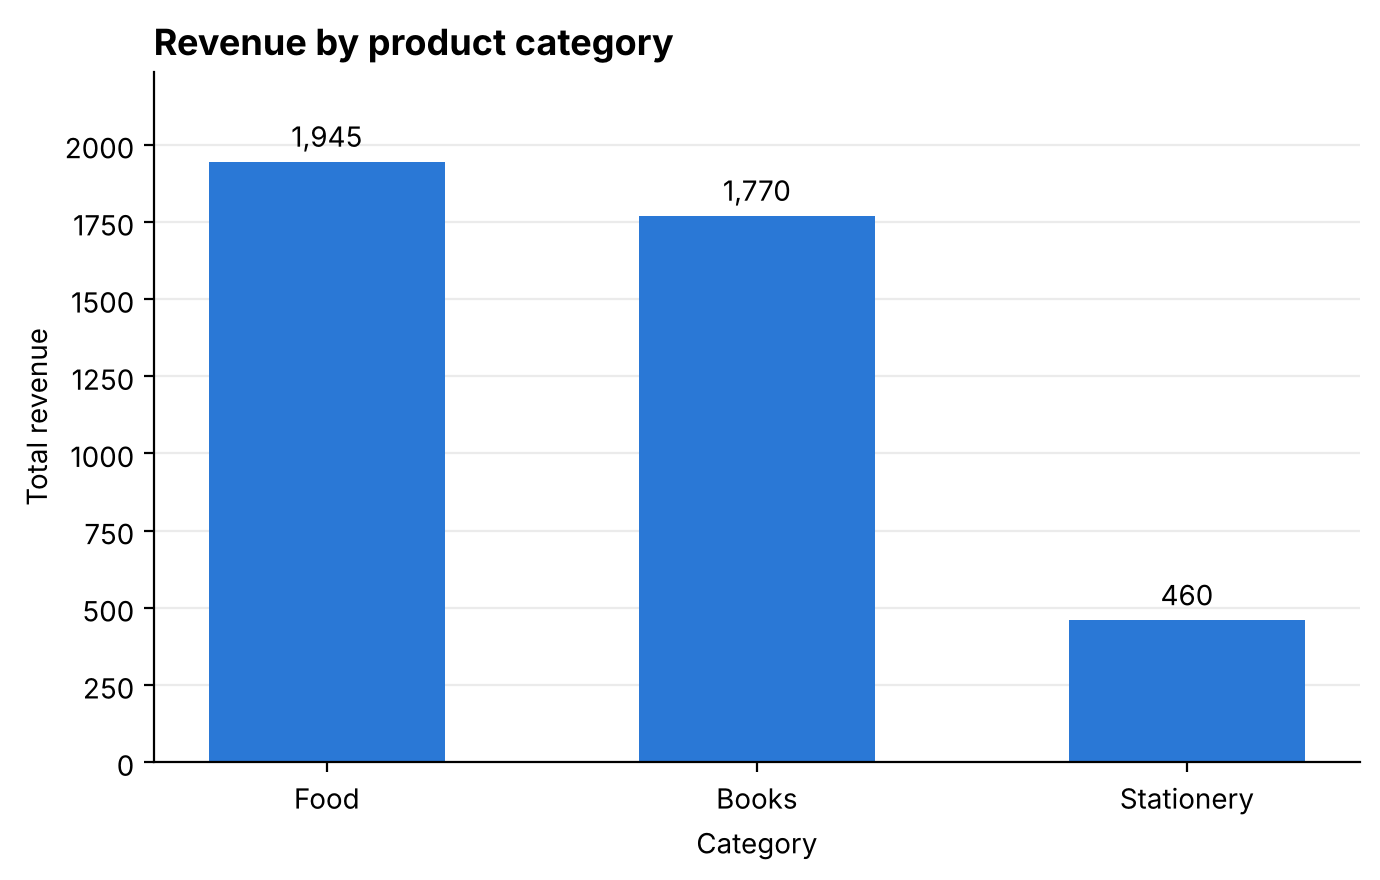

In [9]:
BAR_COLOR = "#2a78d6"

def bar_chart(series, title, xlabel, filename):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    bars = ax.bar(series.index, series.values, color=BAR_COLOR, width=0.55)
    ax.bar_label(bars, labels=[f"{v:,.0f}" for v in series.values], padding=3)
    ax.set_title(title, loc="left", fontsize=13, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Total revenue")
    ax.set_ylim(0, series.max() * 1.15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.yaxis.grid(True, alpha=0.25)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(filename, dpi=150)
    plt.show()

bar_chart(by_category, "Revenue by product category", "Category", "revenue_by_category.png")

### Chart 2: Revenue by region

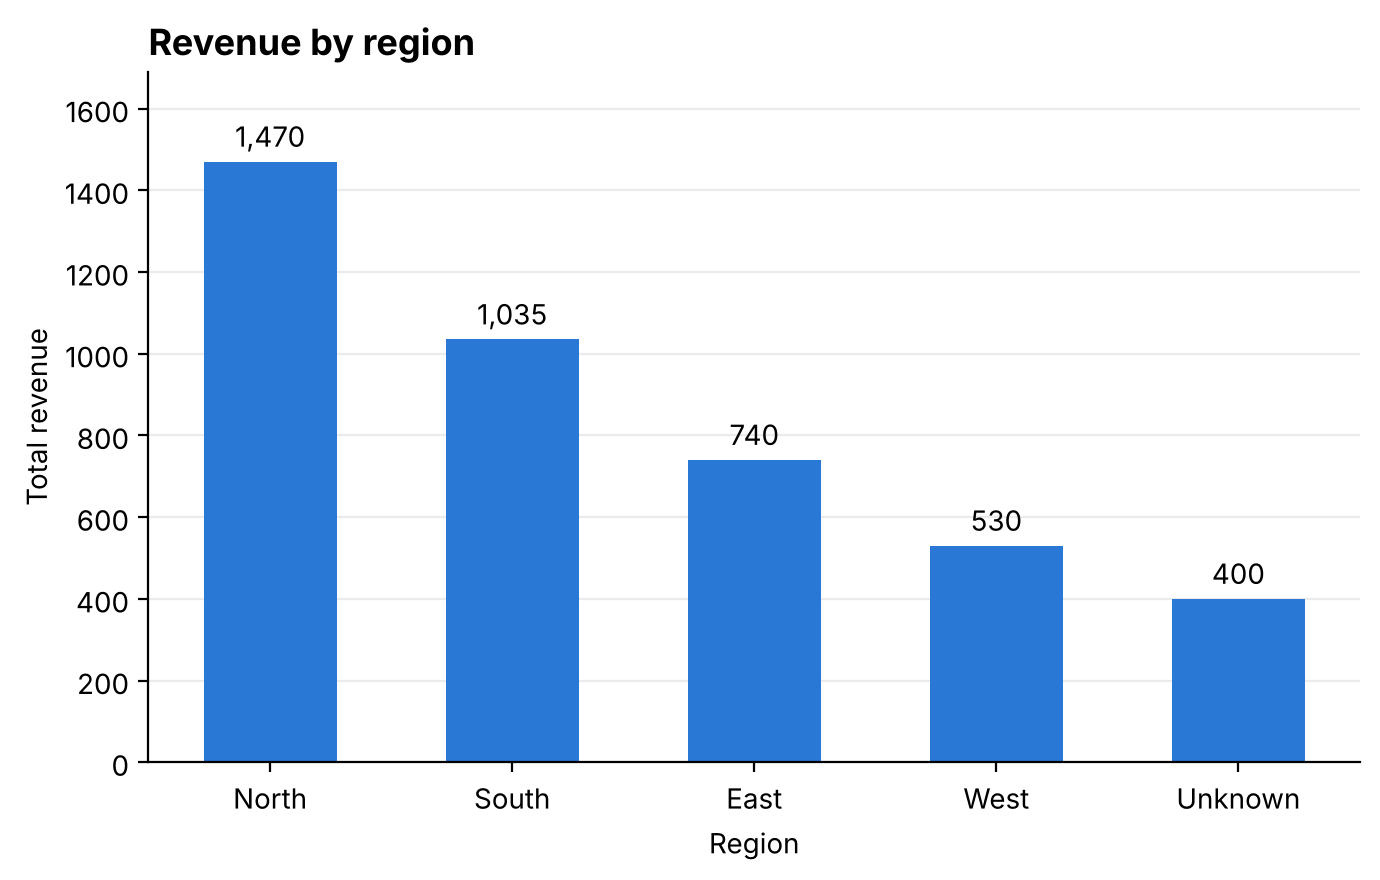

In [10]:
bar_chart(by_region, "Revenue by region", "Region", "revenue_by_region.png")

### Two evidence-based findings

**Finding 1: Food and Books generate almost 90% of revenue, but in very different ways.**
Food earns the most revenue (1,945, or 46.6% of the 4,175 total), followed closely by Books (1,770, or 42.4%). Stationery adds only 460 (11.0%).
Food gets there through volume: 19 units over 6 sales at about 102 per unit. Books reaches nearly the same revenue with just 7 units over 5 sales, at about 253 per unit.
Books is the high-value category, so each Books sale matters far more than a Food sale.

**Finding 2: North is the strongest region and West is the weakest of the known regions.**
North brings in 1,470, which is 35.2% of total revenue and more than any other region, from 5 of the 14 clean transactions. South is next with 1,035, then East (740) and West (530).
A further 400 comes from one sale with no recorded region (`Unknown`). That is a sizeable amount next to West's 530 from two sales, so fixing missing regions at data entry would sharpen any regional comparison.

*Caveat: the cleaned data has only 14 transactions over 10 days, so these patterns are indicative, not conclusive.*

## 4. Save the result

In [11]:
df.to_csv(CLEAN_FILE, index=False)
print(f"Saved {CLEAN_FILE}: {df.shape[0]} rows x {df.shape[1]} columns")

Saved cleaned_sales.csv: 14 rows x 7 columns


---
# PART B: CSV File Handling & Manipulation
Edit the CSV created in Part A and save the result separately as `sales_updated.csv`.
## 1. Read and add a column

In [12]:
sales = pd.read_csv(CLEAN_FILE)
print("Loaded", CLEAN_FILE, "with shape", sales.shape)

sales["tax_amount"] = sales["revenue"] * 0.05   # 5% of revenue
sales.head()   # first five rows

Loaded cleaned_sales.csv with shape (14, 7)


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.0
1,1002,2026-10-01,South,Books,1,250.0,250.0,12.5
2,1003,2026-10-02,North,Food,3,110.0,330.0,16.5
3,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.0
4,1005,2026-10-03,South,Books,2,250.0,500.0,25.0


## 2. Update and remove

**a) Increase the `unit_price` of Books items by 10% using `.loc[]`, then recalculate `revenue` and `tax_amount`.**

In [13]:
books = sales["category"] == "Books"
print("Books rows before the update:")
print(sales.loc[books, ["transaction_id", "category", "quantity", "unit_price", "revenue", "tax_amount"]])

sales.loc[books, "unit_price"] = sales.loc[books, "unit_price"] * 1.10

# Recalculate the dependent columns for ALL rows (non-Books rows are unchanged)
sales["revenue"] = sales["quantity"] * sales["unit_price"]
sales["tax_amount"] = sales["revenue"] * 0.05

print("\nBooks rows after the +10% update:")
print(sales.loc[books, ["transaction_id", "category", "quantity", "unit_price", "revenue", "tax_amount"]])

Books rows before the update:
    transaction_id category  quantity  unit_price  revenue  tax_amount
1             1002    Books         1       250.0    250.0        12.5
4             1005    Books         2       250.0    500.0        25.0
6             1008    Books         1       300.0    300.0        15.0
8             1012    Books         1       320.0    320.0        16.0
11            1018    Books         2       200.0    400.0        20.0

Books rows after the +10% update:
    transaction_id category  quantity  unit_price  revenue  tax_amount
1             1002    Books         1       275.0    275.0       13.75
4             1005    Books         2       275.0    550.0       27.50
6             1008    Books         1       330.0    330.0       16.50
8             1012    Books         1       352.0    352.0       17.60
11            1018    Books         2       220.0    440.0       22.00


**b) Remove one selected row using an existing `transaction_id`.**
Transaction `1018` is selected because its region is `Unknown`, so it is the least reliable record.

In [14]:
target_id = 1018
assert target_id in sales["transaction_id"].values, "transaction_id not found"

rows_before = len(sales)
sales = sales[sales["transaction_id"] != target_id].reset_index(drop=True)
print(f"Removed transaction {target_id}: {rows_before} rows -> {len(sales)} rows")

Removed transaction 1018: 14 rows -> 13 rows


**c) Create a temporary `review_status` column, then remove it with `drop(columns=...)`.**

In [15]:
sales["review_status"] = "pending"
print("With temporary column:", list(sales.columns))

sales = sales.drop(columns=["review_status"])
print("After drop           :", list(sales.columns))

With temporary column: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount', 'review_status']
After drop           : ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']


## 3. Save and verify

In [16]:
sales.to_csv(UPDATED_FILE, index=False)

check = pd.read_csv(UPDATED_FILE)   # read it back from disk
print("First five rows of the saved file:")
display(check.head())
print("Final column names:", list(check.columns))
print("Final shape:", check.shape)

First five rows of the saved file:


,transaction_id,sale_date,region,category,quantity,unit_price,revenue,tax_amount
0,1001,2026-10-01,North,Food,2,120.0,240.0,12.00
1,1002,2026-10-01,South,Books,1,275.0,275.0,13.75
2,1003,2026-10-02,North,Food,3,110.0,330.0,16.50
3,1004,2026-10-02,East,Stationery,4,50.0,200.0,10.00
4,1005,2026-10-03,South,Books,2,275.0,550.0,27.50


Final column names: ['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']
Final shape: (13, 8)


---
**Summary of outputs:** `cleaned_sales.csv` (Part A) and `sales_updated.csv` (Part B) were created. The original `sales_raw.csv` was only read and never changed.